<a href="https://colab.research.google.com/github/aini43325018-ui/2025_algoritma_dan_pemrograman/blob/Visi-Komputer---Semester-3/Jobsheet%203%3A%20Teknik%20Regresi%20Gambar.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Praktikum D1 - Regresi dari Citra Sintetis (Prediksi Radius Lingkaran)

(D1) 1: Setup & Generator Dataset

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score

import tensorflow as tf
from tensorflow.keras import layers, models

# Generator 1 sample def
def make_sample(img_size=64, min_r=5, max_r=20):
  r = np.random.randint(min_r, max_r + 1)
  img = np.zeros((img_size, img_size), dtype=np.uint8)

  cx = np.random.randint(r, img_size - r)
  cy = np.random.randint(r, img_size - r)

  cv2.circle(img, (cx, cy), r, (255,), -1)

  img = (img / 255.0).astype(np.float32)

  img3 = np.stack([img, img, img], axis=-1)

  return img3, float(r), (cx, cy)

(D1) 2: "Tebak Apa?" - Tampilkan Contoh Gambar TANPA Label

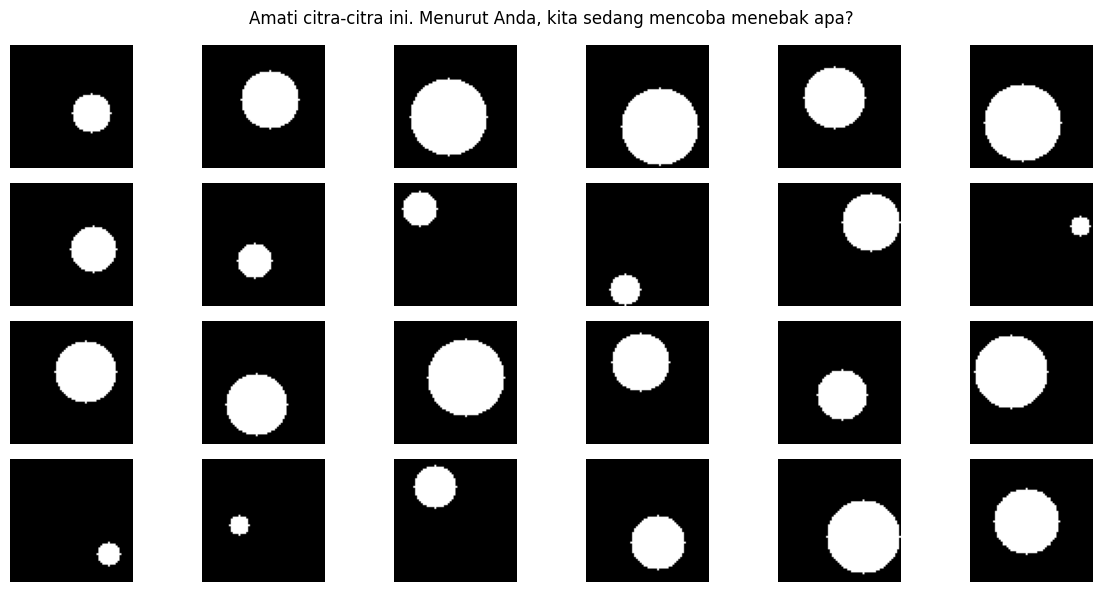

In [ ]:
# Buat 24 contoh untuk visualisasi
N_show = 24
samples = [make_sample() for _ in range(N_show)]
imgs = [s[0] for s in samples]
rads = [s[1] for s in samples]
centers = [s[2] for s in samples]

# Grid gambar tanpa label:
cols = 6
rows = N_show // cols
plt.figure(figsize=(12, 6))
for i in range(N_show):
  plt.subplot(rows, cols, i+1)
  plt.imshow(imgs[i].squeeze(), cmap='gray')
  plt.axis('off')
plt.suptitle("Amati citra-citra ini. Menurut Anda, kita sedang mencoba menebak apa?")
plt.tight_layout()
plt.show()

(D1) 3: Buka Jawaban - Target yang Ingin Diprediksi

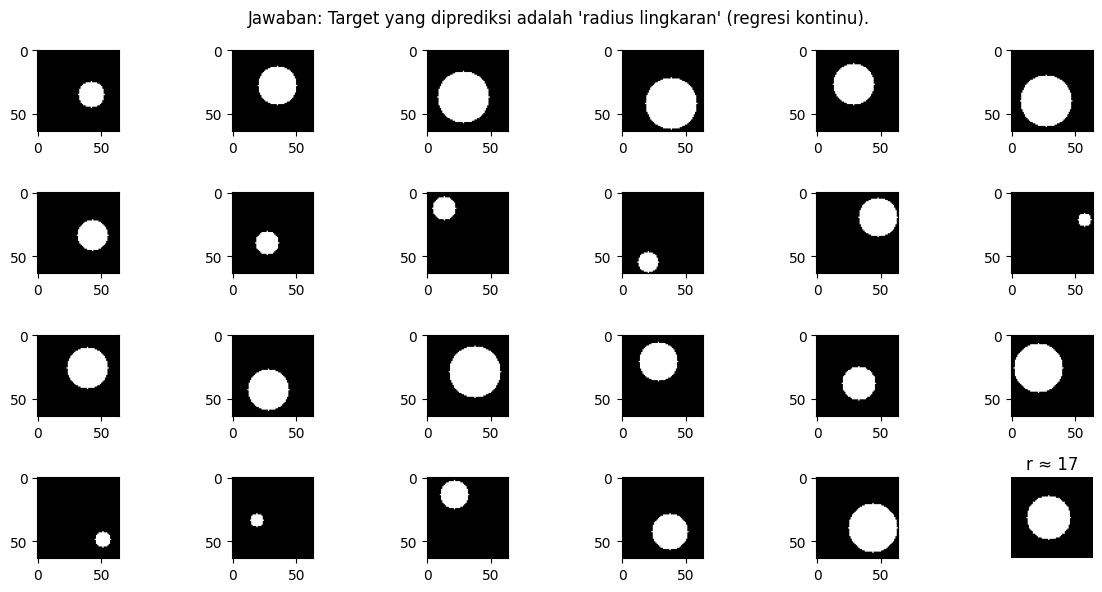

In [ ]:
# Tampilkan kembali, sekarang tampilkan radius (label) di judul tiap subplot
plt.figure(figsize=(12, 6))
for i in range(N_show):
  plt.subplot(rows, cols, i+1)
  plt.imshow(imgs[i].squeeze(), cmap='gray')
plt.title(f"r ≈ {int(rads[i])}")
plt.axis('off')
plt.suptitle("Jawaban: Target yang diprediksi adalah 'radius lingkaran' (regresi kontinu).")
plt.tight_layout()
plt.show()

(D1) 4: Latih CNN Kecil untuk Memprediksi Radius

In [ ]:
# Siapkan dataset lebih besar untuk training
N = 3000
X_tuple, y_tuple, c_tuple = zip(*[make_sample() for _ in range(N)])
X = np.array(X_tuple, dtype=np.float32)
y = np.array(y_tuple, dtype=np.float32)

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42)

# Model CNN sederhana
model = models.Sequential([
    layers.Input((64, 64, 3)),
    layers.Conv2D(32, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation='relu'),
    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation='relu'),
    layers.Dense(1)  # output regresi tunggal (radius)
])

model.compile(optimizer='adam', loss='mse', metrics=['mae'])

# Proses Training (epochs diset ke 12 sesuai panduan)
history = model.fit(Xtr, ytr, validation_data=(Xte, yte),
                    epochs=12, batch_size=64, verbose=0)

# Evaluasi performa model
y_pred = model.predict(Xte).ravel()
mae = mean_absolute_error(yte, y_pred)
rmse = float(np.sqrt(np.mean((yte - y_pred) ** 2)))
r2 = r2_score(yte, y_pred)

print(f"MAE={mae:.3f} | RMSE={rmse:.3f} | R²={r2:.3f}")

19/19 ━━━━━━━━━━━━━━━━━━━━ 2s 111ms/step
MAE=0.981 | RMSE=1.195 | R²=0.935


(D1) 4: Plot History & True vs Predicted

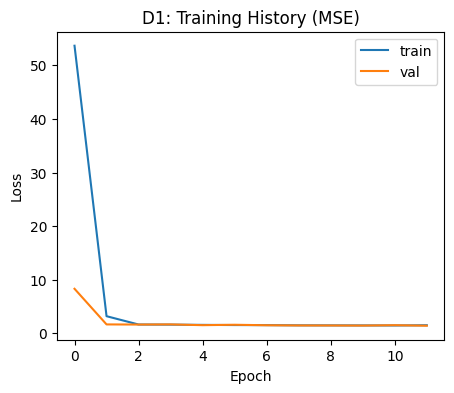

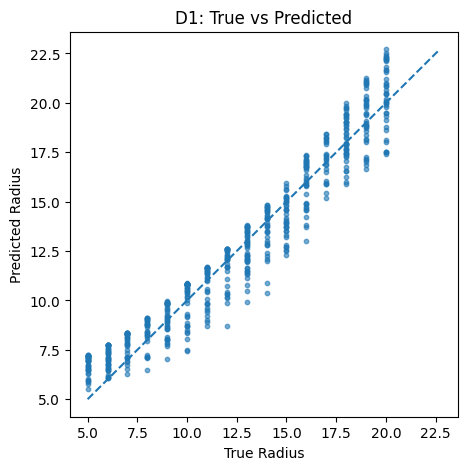

In [ ]:
# Plot loss

plt.figure(figsize=(5,4))
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='val')
plt.title("D1: Training History (MSE)")
plt.xlabel("Epoch");
plt.ylabel("Loss");
plt.legend();
plt.show()

# Scatter True vs Pred

plt.figure(figsize=(5,5))
plt.scatter(yte, y_pred, s=10, alpha=0.6)
lims = [min(yte.min(), y_pred.min()), max(yte.max(), y_pred.max())]
plt.plot(lims, lims, '--')
plt.xlabel("True Radius");
plt.ylabel("Predicted Radius")
plt.title("D1: True vs Predicted")
plt.show()


(D1) 5: Tantangan Mini

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
import tensorflow as tf
from tensorflow.keras import layers, models

# 1. Generator dengan rentang radius 8-28
def make_sample_modified(img_size=64, min_r=8, max_r=28):
    r = np.random.randint(min_r, max_r + 1)
    img = np.zeros((img_size, img_size), dtype=np.uint8)

    cx = np.random.randint(r, img_size - r)
    cy = np.random.randint(r, img_size - r)

    cv2.circle(img, (cx, cy), r, (255,), -1)
    img = (img / 255.0).astype(np.float32)

    img3 = np.stack([img, img, img], axis=-1)
    return img3, float(r), (cx, cy)

# 2. Fungsi penambah noise Gaussian
def add_noise(img, noise_level=0.1):
    noise = np.random.normal(0, noise_level, img.shape)
    noisy_img = np.clip(img + noise, 0, 1)
    return noisy_img.astype(np.float32)

# Siapkan 3000 dataset
N = 3000
samples = [make_sample_modified(min_r=8, max_r=28) for _ in range(N)]

X_clean = np.array([s[0] for s in samples], dtype=np.float32)
y_r = np.array([s[1] for s in samples], dtype=np.float32)
y_c = np.array([s[2] for s in samples], dtype=np.float32)

# Terapkan noise pada seluruh citra
X_noisy = np.array([add_noise(img) for img in X_clean])

# 3. Gabungkan target menjadi multi-output [r, cx, cy]
y_multi = np.column_stack((y_r, y_c))

Xtr, Xte, ytr, yte = train_test_split(X_noisy, y_multi, test_size=0.2, random_state=42)

# Bangun Arsitektur CNN Multi-Output
model = models.Sequential([
    layers.Input((64, 64, 3)),
    layers.Conv2D(32, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation='relu'),
    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation='relu'),
    layers.Dense(3)  # Output regresi 3 nilai: [r, cx, cy]
])

model.compile(optimizer='adam', loss='mse', metrics=['mae'])

# Proses Training (diset ke 15 epochs karena dataset lebih kompleks)
history = model.fit(Xtr, ytr, validation_data=(Xte, yte),
                    epochs=15, batch_size=64, verbose=1)

# Evaluasi Performa secara terpisah
y_pred = model.predict(Xte)

mae_radius = mean_absolute_error(yte[:, 0], y_pred[:, 0])
mae_center_x = mean_absolute_error(yte[:, 1], y_pred[:, 1])
mae_center_y = mean_absolute_error(yte[:, 2], y_pred[:, 2])

print(f"MAE Radius   : {mae_radius:.3f}")
print(f"MAE Center X : {mae_center_x:.3f}")
print(f"MAE Center Y : {mae_center_y:.3f}")

Epoch 1/15
38/38 ━━━━━━━━━━━━━━━━━━━━ 22s 522ms/step - loss: 336.3077 - mae: 14.0809 - val_loss: 103.6281 - val_mae: 7.2914
Epoch 2/15
38/38 ━━━━━━━━━━━━━━━━━━━━ 20s 524ms/step - loss: 67.9738 - mae: 6.1160 - val_loss: 60.5000 - val_mae: 5.9139
Epoch 3/15
38/38 ━━━━━━━━━━━━━━━━━━━━ 20s 509ms/step - loss: 53.0346 - mae: 5.2700 - val_loss: 53.4776 - val_mae: 5.0571
Epoch 4/15
38/38 ━━━━━━━━━━━━━━━━━━━━ 19s 474ms/step - loss: 49.1408 - mae: 4.7733 - val_loss: 50.9671 - val_mae: 4.8254
Epoch 5/15
38/38 ━━━━━━━━━━━━━━━━━━━━ 22s 516ms/step - loss: 47.1901 - mae: 4.6520 - val_loss: 48.6177 - val_mae: 4.7643
Epoch 6/15
38/38 ━━━━━━━━━━━━━━━━━━━━ 19s 470ms/step - loss: 45.8554 - mae: 4.6009 - val_loss: 47.5882 - val_mae: 4.6473
Epoch 7/15
38/38 ━━━━━━━━━━━━━━━━━━━━ 22s 511ms/step - loss: 45.3824 - mae: 4.5876 - val_loss: 45.6726 - val_mae: 4.6129
Epoch 8/15
38/38 ━━━━━━━━━━━━━━━━━━━━ 19s 477ms/step - loss: 42.5104 - mae: 4.3973 - val_loss: 43.4850 - val_mae: 4.4442
Epoch 9/15
38/38 ━━━━━━━━━━━━

Praktium D2: Menebak Umur Manusia dari Foto Wajah (UTKFace)

(D2) 1 - 2: Membuat Akun Kaggle dan Mengunggah Kaggle ke Colab

In [ ]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"nurainiwidiyantiti","key":"f9b14f56d57417a3492e6c66100a2ae6"}'}

In [ ]:
import os, shutil
if os.path.exists("kaggle.json"):
  os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
  shutil.copy("kaggle.json", os.path.expanduser("~/.kaggle/kaggle.json"))
  os.chmod(os.path.expanduser("~/.kaggle/kaggle.json"), 0o600)
  !pip -q install kaggle
  print("✅ Kaggle API siap digunakan.")
else:
  print("❌ kaggle.json belum ditemukan. Upload terlebih dahulu.")

✅ Kaggle API siap digunakan.


(D2) 3: Mengunduh Dataset UTKFace dari Kaggle

In [ ]:
# Unduh dataset UTKFace
!kaggle datasets download -d jangedoo/utkface-new -p /content -q
!unzip -q /content/utkface-new.zip -d /content/utkface
print("✅ Dataset UTKFace berhasil diekstrak.")

Dataset URL: https://www.kaggle.com/datasets/jangedoo/utkface-new
License(s): copyright-authors
✅ Dataset UTKFace berhasil diekstrak.


(D2) 4: Menampilkan Contoh Gambar Dataset

Total gambar ditemukan: 23708


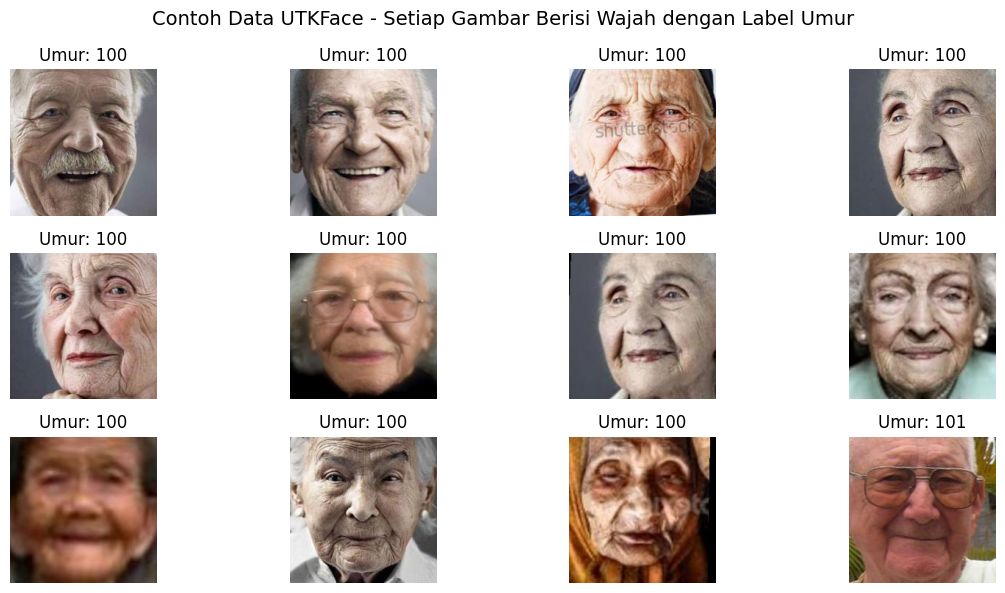

In [ ]:
import matplotlib.pyplot as plt
import os, glob
from PIL import Image

# Ambil 12 gambar acak dari dataset
files = glob.glob("/content/utkface/UTKFace/*.jpg")
files = sorted(files)
print(f"Total gambar ditemukan: {len(files)}")

plt.figure(figsize=(12,6))
for i, f in enumerate(files[:12]):
  # Ambil umur dari nama file
  age = int(os.path.basename(f).split("_")[0])
  img = Image.open(f)
  plt.subplot(3, 4, i + 1)
  plt.imshow(img)
  plt.title(f"Umur: {age}")
  plt.axis("off")

plt.suptitle("Contoh Data UTKFace - Setiap Gambar Berisi Wajah dengan Label Umur", fontsize = 14)
plt.tight_layout()
plt.show()

(D2) 5: Siapkan Dataset untuk Model

In [ ]:
import tensorflow as tf
import numpy as np
from sklearn.model_selection import train_test_split

def parse_age_from_name(fp):
  return int(os.path.basename(fp).split('_')[0])

ages = np.array([parse_age_from_name(f) for f in files], dtype=np.float32).reshape(-1, 1)

train_files, test_files, y_train, y_test = train_test_split(
    files, ages, test_size=0.2, random_state=42
)

IMG_SIZE = 160

def load_img(fp, label):
  img = tf.io.read_file(fp)
  img = tf.image.decode_jpeg(img, channels=3)
  img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
  return img / 255.0, label

train_ds = tf.data.Dataset.from_tensor_slices((train_files, y_train)).map(load_img).batch(64)
test_ds = tf.data.Dataset.from_tensor_slices((test_files, y_test)).map(load_img).batch(64)

print("✅ Dataset siap dilatih.")


✅ Dataset siap dilatih.


(D2): 6: Membangun Model dengan Transfer Learning

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import mean_absolute_error, r2_score
import matplotlib.pyplot as plt
import numpy as np

# Gunakan GPU jika tersedia
print("Hardware:", "GPU" if tf.config.list_physical_devices('GPU') else "CPU")

# Buat arsitektur model
base_model = tf.keras.applications.MobileNetV2(
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    weights='imagenet'
)

base_model.trainable = False
# Tahap awal: freeze backbone

# Tambahkan head regresi
inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs * 255.0)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
x = layers.Dense(128, activation='relu')(x)
outputs = layers.Dense(2)(x)

model = tf.keras.Model(inputs, outputs)

# Kompilasi model

model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss = 'mse', metrics=['mae'])
model.summary()

Hardware: CPU


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ multiply_1 (Multiply)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_1 (TrueDivide)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract_1 (Subtract)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,210 (9.24 MB)

 Trainable params: 164,226 (641.51 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

(D2) 7: Melatih Model (Tahap 1 - Frozen)

Epoch 1/10
297/297 ━━━━━━━━━━━━━━━━━━━━ 571s 2s/step - loss: 243.0801 - mae: 11.5995 - val_loss: 162.0874 - val_mae: 9.6773 - learning_rate: 0.0010
Epoch 2/10
297/297 ━━━━━━━━━━━━━━━━━━━━ 561s 2s/step - loss: 154.0060 - mae: 9.2667 - val_loss: 148.4792 - val_mae: 9.1819 - learning_rate: 0.0010
Epoch 3/10
297/297 ━━━━━━━━━━━━━━━━━━━━ 558s 2s/step - loss: 144.5660 - mae: 8.9153 - val_loss: 145.0276 - val_mae: 9.0532 - learning_rate: 0.0010
Epoch 4/10
297/297 ━━━━━━━━━━━━━━━━━━━━ 556s 2s/step - loss: 140.7989 - mae: 8.7530 - val_loss: 141.4764 - val_mae: 8.9193 - learning_rate: 0.0010
Epoch 5/10
297/297 ━━━━━━━━━━━━━━━━━━━━ 558s 2s/step - loss: 137.1242 - mae: 8.6582 - val_loss: 140.2210 - val_mae: 8.8210 - learning_rate: 0.0010
Epoch 6/10
297/297 ━━━━━━━━━━━━━━━━━━━━ 518s 2s/step - loss: 136.3823 - mae: 8.5938 - val_loss: 139.5706 - val_mae: 8.8231 - learning_rate: 0.0010
Epoch 7/10
297/297 ━━━━━━━━━━━━━━━━━━━━ 558s 2s/step - loss: 133.0014 - mae: 8.4923 - val_loss: 136.1286 - val_mae: 8

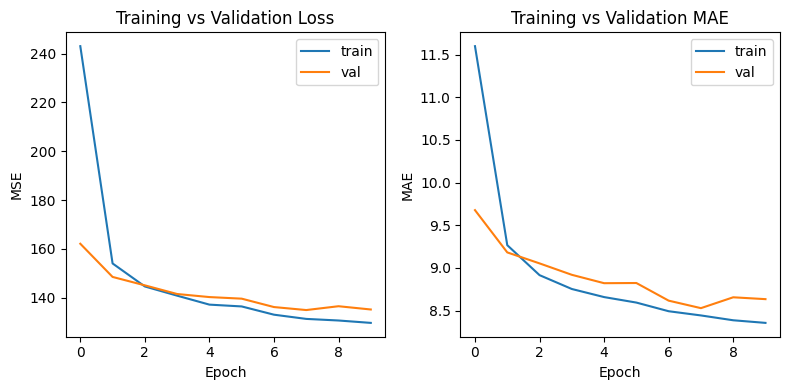

In [ ]:
# Callback untuk pelatihan yang lebih stabil
cb = [
    tf.keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True, monitor='val_loss'),
    tf.keras.callbacks.ReduceLROnPlateau(patience=2, factor=0.5, min_lr=1e-5, monitor='val_loss')
]

history = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=10,
    callbacks=cb,
    verbose=1
)

# Visualisasi perubahan loss dan MAE selama pelatihan:
plt.figure(figsize=(8,4))

plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='val')
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.title('Training vs Validation Loss')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['mae'], label='train')
plt.plot(history.history['val_mae'], label='val')
plt.xlabel('Epoch')
plt.ylabel('MAE')
plt.title('Training vs Validation MAE')
plt.legend()

plt.tight_layout()
plt.show()

(D2) 8: Fine-tuning Backbone (Tahap 2)

Epoch 1/5
297/297 ━━━━━━━━━━━━━━━━━━━━ 727s 2s/step - loss: 147.1800 - mae: 8.8861 - val_loss: 144.5679 - val_mae: 8.7562 - learning_rate: 1.0000e-04
Epoch 2/5
297/297 ━━━━━━━━━━━━━━━━━━━━ 719s 2s/step - loss: 71.1245 - mae: 6.2999 - val_loss: 114.8560 - val_mae: 7.9826 - learning_rate: 1.0000e-04
Epoch 3/5
297/297 ━━━━━━━━━━━━━━━━━━━━ 718s 2s/step - loss: 48.3094 - mae: 5.2277 - val_loss: 107.8520 - val_mae: 7.7341 - learning_rate: 1.0000e-04
Epoch 4/5
297/297 ━━━━━━━━━━━━━━━━━━━━ 711s 2s/step - loss: 35.3490 - mae: 4.4903 - val_loss: 108.4649 - val_mae: 7.7540 - learning_rate: 1.0000e-04
Epoch 5/5
297/297 ━━━━━━━━━━━━━━━━━━━━ 709s 2s/step - loss: 28.7669 - mae: 4.0493 - val_loss: 101.1790 - val_mae: 7.2288 - learning_rate: 1.0000e-04


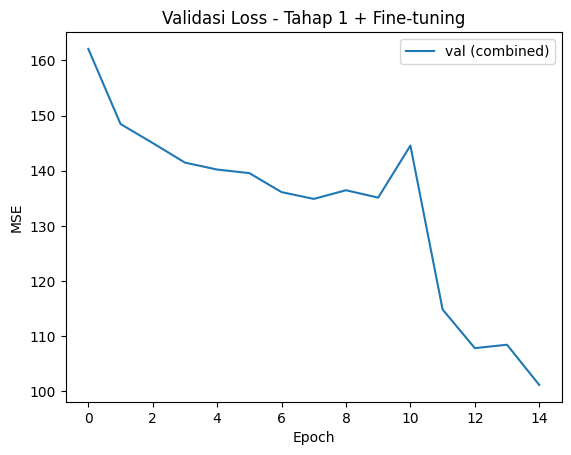

In [ ]:
# Aktifkan kembali sebagian layer terakhir untuk fine-tuning base
base_model.trainable = True

for layer in base_model.layers[:-30]:
  layer.trainable = False

model.compile(optimizer=tf.keras.optimizers.Adam(1e-4),
              loss='mse', metrics=['mae'])

history_ft = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=5,
    callbacks=cb,
    verbose=1
)

plt.plot(history.history['val_loss'] + history_ft.history['val_loss'], label='val (combined)')
plt.title("Validasi Loss - Tahap 1 + Fine-tuning")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.legend()
plt.show()

(D2) 9: Evaluasi Akhir (MAE, RMSE, R²)

MAE = 7.23 tahun
RMSE = 26.57 tahun
R² = 0.745


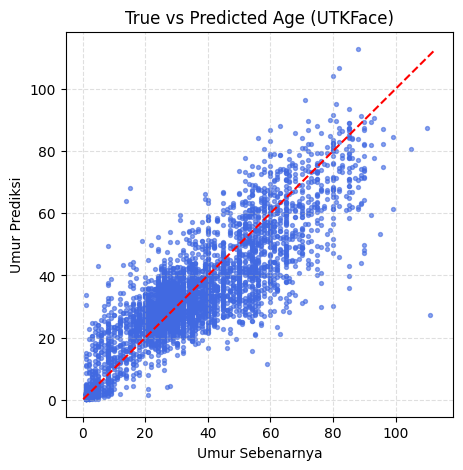

In [ ]:
from math import sqrt
from sklearn.metrics import r2_score

y_pred = np.concatenate([model.predict(batch[0], verbose=0)[:, 0] for batch in test_ds])

mae = mean_absolute_error(y_test, y_pred)
rmse = sqrt(np.mean((y_test - y_pred)**2))
r2 = r2_score(y_test, y_pred)

print(f"MAE = {mae:.2f} tahun")
print(f"RMSE = {rmse:.2f} tahun")
print(f"R² = {r2:.3f}")

# Plot "umur sebenarnya vs umur prediksi":
plt.figure(figsize=(5,5))
plt.scatter(y_test, y_pred, s=8, alpha=0.6, color='royalblue')
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, '--', color='red')
plt.xlabel("Umur Sebenarnya")
plt.ylabel("Umur Prediksi")
plt.title("True vs Predicted Age (UTKFace)")
plt.grid(True, linestyle='--', alpha=0.4)
plt.show()

(D2) 10: Melihat Contoh Prediksi Nyata

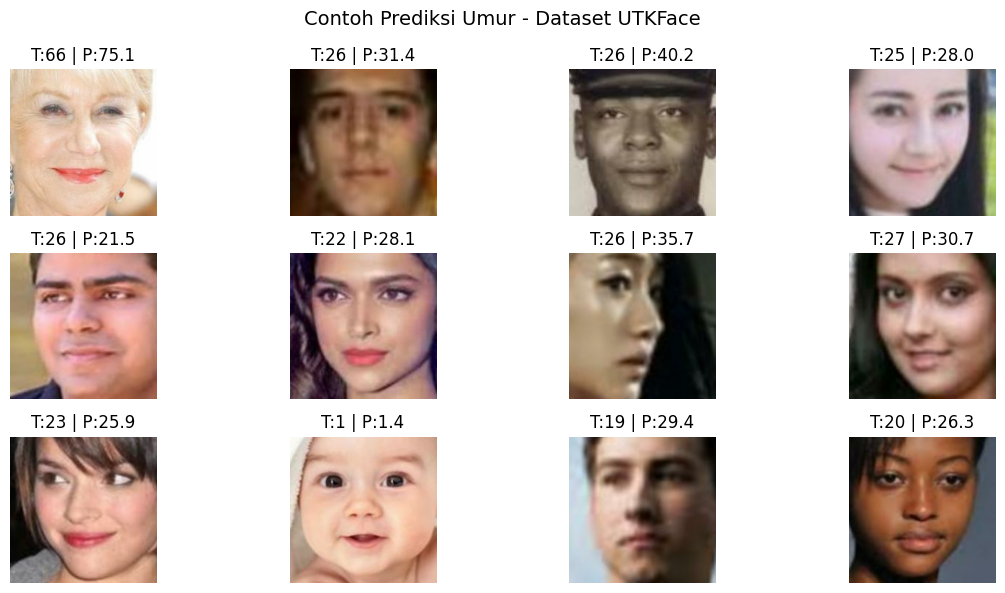

In [ ]:
import random
import os

sample_paths = random.sample(test_files, 12)

plt.figure(figsize=(12,6))
for i, path in enumerate(sample_paths):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))/255.0

    true_age = int(os.path.basename(path).split('_')[0])
    pred_age = model.predict(tf.expand_dims(img, 0), verbose=0).ravel()[0]

    plt.subplot(3,4,i+1)
    plt.imshow(img.numpy())
    plt.title(f"T:{true_age} | P:{pred_age:.1f}")
    plt.axis('off')

plt.suptitle("Contoh Prediksi Umur - Dataset UTKFace", fontsize=14)
plt.tight_layout()
plt.show()

Praktikum D3: Menilai "Kepopuleran Hewan Peliharaan" dari Foto

(D3) 1: Menyiapkan Kaggle API

In [3]:
from google.colab import files
files.upload()

import os, shutil

if os.path.exists("kaggle.json"):
    os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
    shutil.copy("kaggle.json", os.path.expanduser("~/.kaggle/kaggle.json"))
    os.chmod(os.path.expanduser("~/.kaggle/kaggle.json"), 0o600)
    !pip -q install kaggle
    print("✅ Kaggle API siap digunakan.")
else:
    print("❌ kaggle.json belum ditemukan. Upload terlebih dahulu.")

Saving kaggle.json to kaggle.json
✅ Kaggle API siap digunakan.


(D3) 2: Mengunduh dan Mengesktrak Dataset

In [7]:
# Unduh dataset Pawpularity (sekitar 800MB)
!kaggle competitions download -c petfinder-pawpularity-score -p /content -q
!unzip -q /content/petfinder-pawpularity-score.zip -d /content/paw

print("✅ Dataset Pawpularity berhasil diekstrak.")

✅ Dataset Pawpularity berhasil diekstrak.


(D3) 3: Melihat Contoh Data

                                 Id  Subject Focus  Eyes  Face  Near  Action  \
0  0007de18844b0dbbb5e1f607da0606e0              0     1     1     1       0   
1  0009c66b9439883ba2750fb825e1d7db              0     1     1     0       0   
2  0013fd999caf9a3efe1352ca1b0d937e              0     1     1     1       0   
3  0018df346ac9c1d8413cfcc888ca8246              0     1     1     1       0   
4  001dc955e10590d3ca4673f034feeef2              0     0     0     1       0   

   Accessory  Group  Collage  Human  Occlusion  Info  Blur  Pawpularity  \
0          0      1        0      0          0     0     0           63   
1          0      0        0      0          0     0     0           42   
2          0      0        0      1          1     0     0           28   
3          0      0        0      0          0     0     0           15   
4          0      1        0      0          0     0     0           72   

                                                path  
0  /content/p

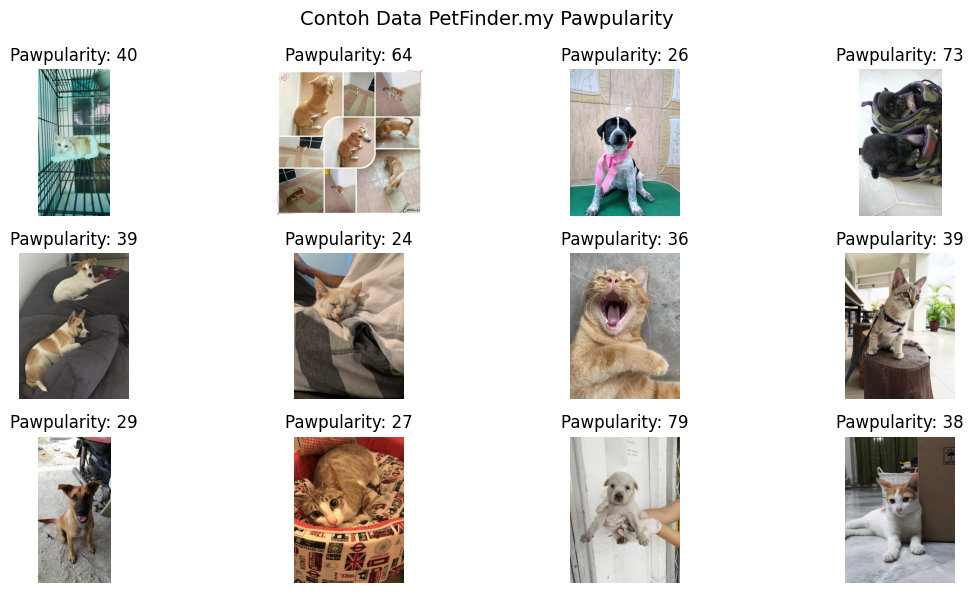

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import os
from PIL import Image

# Muat CSV
df = pd.read_csv('/content/paw/train.csv')
df['path'] = df['Id'].apply(lambda x: f"/content/paw/train/{x}.jpg")
print(df.head())

# Tampilkan 12 contoh gambar
plt.figure(figsize=(12, 6))
for i, row in enumerate(df.sample(12, random_state=42).itertuples()):
  img = Image.open(row.path)
  plt.subplot(3, 4, i + 1)
  plt.imshow(img)
  plt.title(f"Pawpularity: {row.Pawpularity}")
  plt.axis('off')

plt.suptitle("Contoh Data PetFinder.my Pawpularity", fontsize=14)
plt.tight_layout()
plt.show()

(D3) 4: Persiapan Dataset

In [11]:
from sklearn.model_selection import train_test_split
import tensorflow as tf

IMG_SIZE = 224

train_df, val_df = train_test_split(df, test_size=0.2, random_state=42)
def load_image(path, label):
  img = tf.io.read_file(path)
  img = tf.image.decode_jpeg(img, channels=3)
  img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
  img = tf.cast(img, tf.float32) / 255.0
  return img, tf.cast(label, tf.float32)

train_ds = tf.data.Dataset.from_tensor_slices((train_df['path'], train_df['Pawpularity'])) \
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE) \
    .shuffle(4096).batch(64).prefetch(tf.data.AUTOTUNE)

val_ds = tf.data.Dataset.from_tensor_slices((val_df['path'], val_df['Pawpularity'])) \
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE) \
    .batch(64).prefetch(tf.data.AUTOTUNE)

print(f"Dataset siap digunakan - {len(train_df)} untuk training, {len(val_df)} untuk validasi.")

Dataset siap digunakan - 7929 untuk training, 1983 untuk validasi.


(D4) 5: Membangun Model (EfficientNetB0)

In [13]:
from tensorflow.keras import layers, models

base = tf.keras.applications.EfficientNetB0(
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    weights='imagenet'
)
base.trainable = False

inputs = tf.keras.Input((IMG_SIZE, IMG_SIZE, 3))
x = tf.keras.applications.efficientnet.preprocess_input(inputs * 255.0)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D() (x)
x = layers.Dropout(0.3) (x)
x = layers.Dense(256, activation='relu') (x)
outputs = layers.Dense(1) (x)

model = tf.keras.Model(inputs, outputs)
model.compile(optimizer='adam', loss='mse', metrics=['mae'])
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ multiply (Multiply)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,377,764 (16.70 MB)

 Trainable params: 328,193 (1.25 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

(D3) 6: Melatih Model

In [16]:
cb = [
    tf.keras.callbacks.EarlyStopping(patience=3,
      restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(patience=2, factor=0.5)
]

history = model.fit(train_ds, validation_data=val_ds, epochs=10, callbacks=cb, verbose=1)

Epoch 1/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 690s 5s/step - loss: 320.7670 - mae: 13.3015 - val_loss: 358.9381 - val_mae: 13.7713 - learning_rate: 0.0010
Epoch 2/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 789s 6s/step - loss: 315.1175 - mae: 13.1454 - val_loss: 355.5957 - val_mae: 13.9438 - learning_rate: 0.0010
Epoch 3/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 875s 7s/step - loss: 303.7911 - mae: 12.9704 - val_loss: 355.3133 - val_mae: 13.9791 - learning_rate: 0.0010
Epoch 4/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 704s 5s/step - loss: 300.9309 - mae: 12.9305 - val_loss: 363.4658 - val_mae: 14.2896 - learning_rate: 0.0010
Epoch 5/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 684s 5s/step - loss: 295.0024 - mae: 12.8212 - val_loss: 356.3536 - val_mae: 13.8101 - learning_rate: 0.0010
Epoch 6/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 688s 5s/step - loss: 285.0897 - mae: 12.6087 - val_loss: 357.2660 - val_mae: 13.6999 - learning_rate: 5.0000e-04


(D3) 7: Melihat Proses Belajar Grafik

<function matplotlib.pyplot.show(close=None, block=None)>

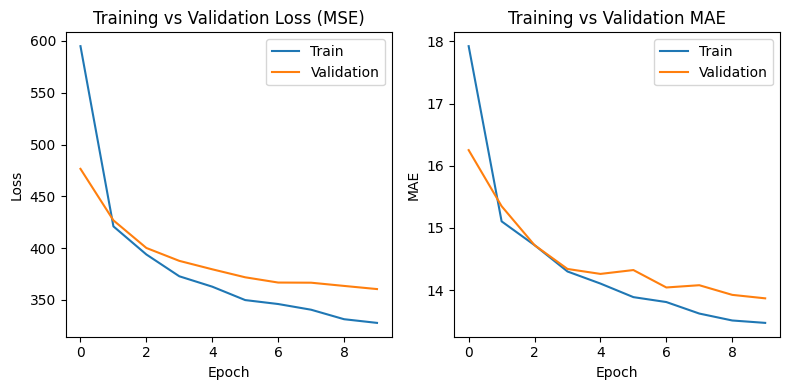

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,4))
plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Validation')
plt.title("Training vs Validation Loss (MSE)")
plt.xlabel("Epoch");
plt.ylabel("Loss");
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['mae'], label='Train')
plt.plot(history.history['val_mae'], label='Validation')
plt.title("Training vs Validation MAE")
plt.xlabel("Epoch");
plt.ylabel("MAE");
plt.legend()
plt.tight_layout()
plt.show

(D3) 8: Evaluasi Model

MAE = 13.98
RMSE= 18.85
R² = 0.196


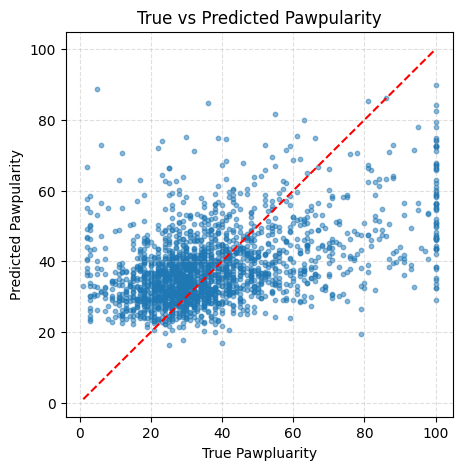

In [18]:
import numpy as np
from sklearn.metrics import mean_absolute_error, r2_score
from math import sqrt
import matplotlib.pyplot as plt

y_true = val_df['Pawpularity'].values.astype(np.float32)
y_pred = np.concatenate([model.predict(batch[0], verbose=0).ravel() for batch in val_ds])
mae = mean_absolute_error(y_true, y_pred)
rmse = sqrt(np.mean((y_true - y_pred)**2))
r2 = r2_score(y_true, y_pred)

print(f"MAE = {mae:.2f}")
print(f"RMSE= {rmse:.2f}")
print(f"R² = {r2:.3f}")

plt.figure(figsize=(5,5))
plt.scatter(y_true, y_pred, s=10, alpha=0.5)
lims = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
plt.plot(lims, lims, '--', color='red')
plt.xlabel("True Pawpluarity")
plt.ylabel("Predicted Pawpularity")
plt.title("True vs Predicted Pawpularity")
plt.grid(True, linestyle='--', alpha=0.4)
plt.show()

(D3) 9: Melihat Contoh Prediksi

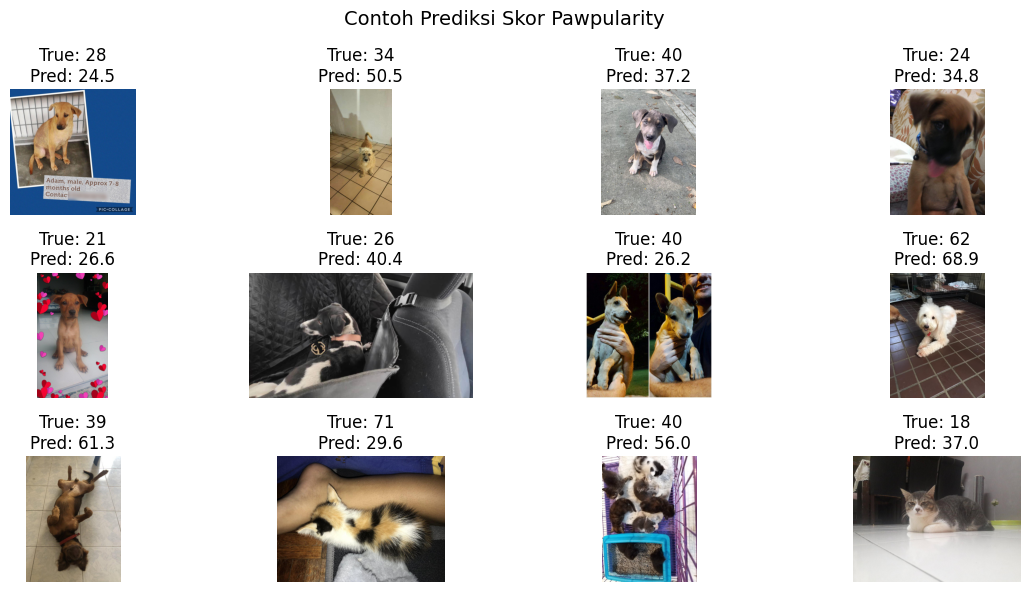

In [19]:
import random
from PIL import Image

sample_rows = val_df.sample(12, random_state=1)

plt.figure(figsize=(12, 6))
for i, row in enumerate(sample_rows.itertuples()):
    img = Image.open(row.path)
    pred = model.predict(tf.expand_dims(load_image(row.path, row.Pawpularity)[0], 0), verbose=0).ravel()[0]

    plt.subplot(3, 4, i + 1)
    plt.imshow(img)
    plt.title(f"True: {row.Pawpularity}\nPred: {pred:.1f}")
    plt.axis('off')

plt.suptitle("Contoh Prediksi Skor Pawpularity", fontsize=14)
plt.tight_layout()
plt.show()

Tantangan Mini

In [25]:
# Membelah data validasi menjadi dua bagian (Dummy split)
tengah = len(val_df) // 2
val_anjing_df = val_df.iloc[:tengah]
val_kucing_df = val_df.iloc[tengah:]

# Buat format TensorFlow Dataset khusus untuk masing-masing bagian
val_ds_anjing = tf.data.Dataset.from_tensor_slices((val_anjing_df['path'], val_anjing_df['Pawpularity'])) \
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE).batch(64)

val_ds_kucing = tf.data.Dataset.from_tensor_slices((val_kucing_df['path'], val_kucing_df['Pawpularity'])) \
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE).batch(64)

In [26]:
# 1. Menambahkan Data Augmentation

from tensorflow.keras import layers, models

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizonral"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

inputs = tf.keras.Input((IMG_SIZE, IMG_SIZE, 3))

x = data_augmentation(inputs)
x = tf.keras.applications.efficientnet.preprocess_input(x * 255.0)

x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(256, activation='relu')(x)
outputs = layers.Dense(1)(x)

model_aug = tf.keras.Model(inputs, outputs)

# 2. Menggunakan Arsitektur Lain (ResNet50)

base_resnet = tf.keras.applications.ResNet50(
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    weights='imagenet'
)
base_resnet.trainable = False

inputs = tf.keras.Input((IMG_SIZE, IMG_SIZE, 3))

x = tf.keras.applications.resnet50.preprocess_input(inputs * 255.0)
x = base_resnet(x, training=False)

# 3. Eksperimen Bias Anjing VS Kucing

y_anjing = val_anjing_df['Pawpularity'].values
y_pred_anjing = np.concatenate([model.predict(batch[0], verbose=0).ravel() for batch in val_ds_anjing])

mae_anjing = mean_absolute_error(y_anjing, y_pred_anjing)
print(f"MAE Khusus Anjing: {mae_anjing:.2f}")

MAE Khusus Anjing: 13.91


Penugasan: Tebak Usia dari Foto Pribadi

Silakan upload foto wajah pribadimu:


Saving aduh kok cakep yh.jpeg to aduh kok cakep yh.jpeg


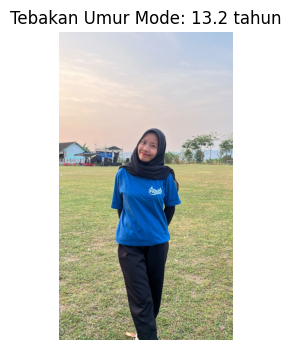

In [30]:
import tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
from google.colab import files
import io

print("Silakan upload foto wajah pribadimu:")
uploaded = files.upload()

for fn in uploaded.keys():
  img = Image.open(io.BytesIO(uploaded[fn])).convert('RGB')

  img_resized = img.resize((160, 160))
  img_array = np.array(img_resized) / 255.0
  img_tensor = tf.expand_dims(img_array, 0)

  pred_age = model.predict(img_tensor, verbose=0).ravel()[0]

  plt.figure(figsize=(4, 4))
  plt.imshow(img)
  plt.axis('off')
  plt.title(f"Tebakan Umur Mode: {pred_age:.1f} tahun")
  plt.show()

Penugasan: Uji Model Pawpularity

Silakan upload foto pribadimu:


Saving aduh kok cakep yh kak.jpeg to aduh kok cakep yh kak (3).jpeg


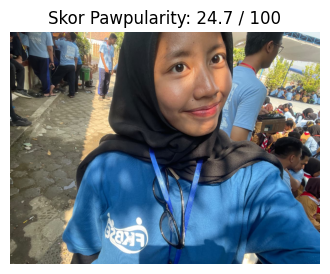

In [38]:
import tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
from google.colab import files
import io

print("Silakan upload foto pribadimu:")
uploaded = files.upload()

for fn in uploaded.keys():
  img = Image.open(io.BytesIO(uploaded[fn])).convert('RGB')

  img_resized = img.resize((224, 224))
  img_array = np.array(img_resized) / 255.0
  img_tensor = tf.expand_dims(img_array, 0)

  pred_paw = model.predict(img_tensor, verbose=0).ravel()[0]

  plt.figure(figsize=(4, 4))
  plt.imshow(img)
  plt.axis('off')
  plt.title(f"Skor Pawpularity: {pred_paw:.1f} / 100")
  plt.show()